# PriViLege (CVPR 2024): reproduction results

Our results for **Table 1**, **Table 3**, **Table 4** and **Figure 3**, each next to the paper's. Every number comes from
one file, `results/all_runs.csv`: one row per experiment, dataset and seed, with the accuracy after every session.
Nothing is trained here, so this runs anywhere in seconds (VS Code, Jupyter, or Colab on a CPU runtime).

- **How the runs were made:** `colab/PriViLege_colab.ipynb` (the authors' code, branch `t4-fixes`), 5 seeds per
  experiment (1 for CLIP zero-shot, which has no training), 5 base epochs and 3 epochs per incremental session.
- **How the file was made:** `python colab/merge_results.py results/raw/*.csv` merges the results files of every
  machine (`results/raw/`) and checks each row against its session list.
- **Metrics:** A_Base = accuracy after the base session, A_Last = after the last session, A_Avg = mean over all sessions.
  Ours are mean ± standard deviation over the seeds; Δ = ours − paper (green within 1 point, orange within 3, red beyond).

## 1. Load the results

In [1]:
import json, os, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Opened from the repo (colab/ or the repo root) it reads the local file; anywhere else it downloads it from GitHub.
URL = 'https://raw.githubusercontent.com/AkilaDissanayake/PriViLege/t4-fixes/results/all_runs.csv'
CSV = next((p for p in ['../results/all_runs.csv', 'results/all_runs.csv'] if os.path.exists(p)), None)
if CSV is None:
    CSV = urllib.request.urlretrieve(URL, 'all_runs.csv')[0]
runs = pd.read_csv(CSV)
runs['sessions'] = runs['sessions'].map(json.loads)
print(f'{len(runs)} runs read from {CSV}')

81 runs read from ../results/all_runs.csv


## 2. Paper numbers and helpers
Paper values are (mean, std) of A_Base, A_Last and A_Avg. Figure 3 has no table: its values were read off the plot
(accuracy per session, within about ± 0.3), so it has no std.

In [2]:
PAPER = {
    'Table 1': {('PriViLege', 'cifar100'):      [(90.88, .20), (86.06, .32), (88.08, .20)],
                ('PriViLege', 'cub200'):        [(82.21, .35), (75.08, .52), (77.50, .33)],
                ('PriViLege', 'mini_imagenet'): [(96.68, .06), (94.10, .13), (95.27, .11)]},
    'Table 3': {('abl_FT', 'cub200'):      [(84.21, .13), (3.79, 1.47), (21.60, 1.32)],
                ('abl_PKT', 'cub200'):     [(79.06, .77), (70.81, .76), (73.36, .77)],
                ('abl_PKT_ED', 'cub200'):  [(80.31, .54), (72.70, .45), (75.04, .40)],
                ('abl_PKT_SKD', 'cub200'): [(82.10, .57), (73.44, .40), (76.27, .30)],
                ('PriViLege', 'cub200'):   [(82.21, .35), (75.08, .52), (77.50, .33)]},
    'Table 4': {('layers_0', 'cub200'):  [(76.07, .56), (60.19, 1.11), (67.08, .71)],
                ('abl_PKT', 'cub200'):   [(79.06, .77), (70.81, .76), (73.36, .77)],
                ('layers_5', 'cub200'):  [(78.42, .84), (68.52, .84), (71.99, .84)],
                ('layers_7', 'cub200'):  [(76.96, .74), (63.15, 2.73), (68.06, 1.54)],
                ('layers_10', 'cub200'): [(74.95, .78), (57.78, 2.30), (64.19, 1.59)],
                ('layers_12', 'cub200'): [(73.62, 2.72), (56.02, 1.47), (62.71, 2.14)]},
}
FIG3 = {   # Figure 3, accuracy per session (base, 1..8), read off the plot
    'clip_zeroshot':   [78.8, 76.6, 75.2, 73.1, 72.5, 72.4, 72.7, 72.3, 71.0],
    'clip_PKT':        [82.3, 79.5, 77.6, 75.4, 74.0, 73.2, 73.3, 72.6, 71.4],
    'clip_PKT_ED':     [83.7, 81.2, 79.8, 77.6, 76.7, 76.3, 76.5, 76.2, 74.7],
    'clip_PKT_ED_SKD': [84.2, 82.1, 81.0, 79.0, 78.8, 78.4, 78.6, 78.3, 77.1],
}
PAPER['Figure 3'] = {(n, 'cifar100'): [(v[0], None), (v[-1], None), (round(float(np.mean(v)), 2), None)]
                     for n, v in FIG3.items()}

LABELS = {'PriViLege': 'PriViLege (Ours)', 'abl_FT': 'Baseline (fine-tune + proto)', 'abl_PKT': 'PKT',
          'abl_PKT_ED': 'PKT + L_ED', 'abl_PKT_SKD': 'PKT + L_SKD', 'layers_0': '0 layers', 'layers_5': '5 layers',
          'layers_7': '7 layers', 'layers_10': '10 layers', 'layers_12': '12 layers',
          'clip_zeroshot': 'CLIP zero-shot', 'clip_PKT': 'CLIP-PKT', 'clip_PKT_ED': 'CLIP-PKT + L_ED',
          'clip_PKT_ED_SKD': 'CLIP-PKT + L_ED + L_SKD',
          'abl_Baseline': 'Baseline, released -ft (not used)'}
DS = {'cub200': 'CUB200', 'cifar100': 'CIFAR-100', 'mini_imagenet': 'miniImageNet'}
METRICS = ['A_Base', 'A_Last', 'A_Avg']

def of(name, ds):
    return runs[(runs['name'] == name) & (runs['dataset'] == ds)]

def ms(x):
    return f'{np.mean(x):.2f} ± {np.std(x, ddof=1) if len(x) > 1 else 0:.2f}'

def label(table, name, ds):
    if table == 'Table 1':
        return DS[ds]
    if table == 'Table 4' and name == 'abl_PKT':
        return '2 layers (= PKT)'
    return LABELS[name]

def color(v):
    if pd.isna(v):
        return ''
    return 'color: green' if abs(v) <= 1 else ('color: orange' if abs(v) <= 3 else 'color: red')

def compare(table):
    rows = []
    for (name, ds), paper in PAPER[table].items():
        r = of(name, ds)
        row = {'': label(table, name, ds), 'seeds': len(r)}
        for m, (pm, ps) in zip(METRICS, paper):
            row[f'{m} ours'] = ms(r[m]) if len(r) else '—'
            row[f'{m} paper'] = f'{pm:.2f}' + (f' ± {ps:.2f}' if ps is not None else ' (fig.)')
            row[f'Δ {m}'] = round(r[m].mean() - pm, 2) if len(r) else np.nan
        rows.append(row)
    df = pd.DataFrame(rows).set_index('')
    display(Markdown(f'**{table}: ours vs. paper**'))
    display(df.style.map(color, subset=[f'Δ {m}' for m in METRICS]).format(precision=2, na_rep='—'))
    return df

def plot_sessions(table, paper_curves=None):
    plt.figure(figsize=(7, 4))
    for i, (name, ds) in enumerate(PAPER[table]):
        r, c, lab = of(name, ds), f'C{i}', label(table, name, ds)
        if len(r):
            acc = np.array(r['sessions'].tolist())
            x = np.arange(acc.shape[1])
            plt.plot(x, acc.mean(0), '-o', color=c, ms=4, label=f'{lab} (ours, n={len(r)})')
            if len(r) > 1:
                sd = acc.std(0, ddof=1)
                plt.fill_between(x, acc.mean(0) - sd, acc.mean(0) + sd, color=c, alpha=.15)
        if paper_curves and name in paper_curves:
            plt.plot(paper_curves[name], '--*', color=c, alpha=.7, label=f'{lab} (paper)')
    plt.xlabel('session (0 = base)'); plt.ylabel('accuracy (%)'); plt.title(f'{table}: accuracy per session')
    plt.grid(alpha=.3); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

def show(table):
    compare(table)
    plot_sessions(table, FIG3 if table == 'Figure 3' else None)

## 3. What is in the file
Seeds per experiment and the GPU time of each run (NVIDIA A40). A run that was interrupted and resumed only records the
time of its last part, so those minutes are too low.

In [3]:
summary = (runs.groupby(['name', 'dataset'], sort=False)
               .agg(seeds=('seed', lambda s: ', '.join(map(str, sorted(s)))),
                    minutes_per_run=('minutes', 'median'), resumed=('resumed', lambda s: (s == 'yes').sum()))
               .rename(index=LABELS, level=0).rename(index=DS, level=1))
display(summary)
print(f"{len(runs)} runs | about {runs['minutes'].sum() / 60:.1f} GPU hours recorded")

seeds  \
name                              dataset                       
PriViLege (Ours)                  CIFAR-100     1, 2, 3, 4, 5   
                                  CUB200        1, 2, 3, 4, 5   
                                  miniImageNet  1, 2, 3, 4, 5   
Baseline (fine-tune + proto)      CUB200        1, 2, 3, 4, 5   
PKT                               CUB200        1, 2, 3, 4, 5   
PKT + L_ED                        CUB200        1, 2, 3, 4, 5   
PKT + L_SKD                       CUB200        1, 2, 3, 4, 5   
0 layers                          CUB200        1, 2, 3, 4, 5   
5 layers                          CUB200        1, 2, 3, 4, 5   
7 layers                          CUB200        1, 2, 3, 4, 5   
10 layers                         CUB200        1, 2, 3, 4, 5   
12 layers                         CUB200        1, 2, 3, 4, 5   
CLIP zero-shot                    CIFAR-100                 1   
CLIP-PKT                          CIFAR-100     1, 2, 3, 4, 5   
CLIP-PKT + L_ED                   CIFAR-100     1, 2, 3, 4, 5   
CLIP-PKT + L_ED + L_SKD           CIFAR-100     1, 2, 3, 4, 5   
Baseline, released -ft (not used) CUB200        1, 2, 3, 4, 5   

                                                minutes_per_run  resumed  
name                              dataset                                 
PriViLege (Ours)                  CIFAR-100                25.4        0  
                                  CUB200                    6.8        0  
                                  miniImageNet             25.9        0  
Baseline (fine-tune + proto)      CUB200                    5.6        2  
PKT                               CUB200                    7.6        0  
PKT + L_ED                        CUB200                    7.0        0  
PKT + L_SKD                       CUB200                    6.9        0  
0 layers                          CUB200                    6.8        0  
5 layers                          CUB200                    7.1        0  
7 layers                          CUB200                    7.0        0  
10 layers                         CUB200                    7.2        0  
12 layers                         CUB200                    7.4        2  
CLIP zero-shot                    CIFAR-100                 4.1        0  
CLIP-PKT                          CIFAR-100                26.8        1  
CLIP-PKT + L_ED                   CIFAR-100                26.9        2  
CLIP-PKT + L_ED + L_SKD           CIFAR-100                26.9        2  
Baseline, released -ft (not used) CUB200                    6.8        1

81 runs | about 15.5 GPU hours recorded


## 4. Table 1: PriViLege on the three benchmarks
CUB200: 100 base classes + 10 sessions of 10-way 5-shot. CIFAR-100 and miniImageNet: 60 base classes + 8 sessions of
5-way 5-shot.

**Table 1: ours vs. paper**

,seeds,A_Base ours,A_Base paper,Δ A_Base,A_Last ours,A_Last paper,Δ A_Last,A_Avg ours,A_Avg paper,Δ A_Avg
,,,,,,,,,,
CIFAR-100,5,90.22 ± 0.24,90.88 ± 0.20,-0.66,85.49 ± 0.32,86.06 ± 0.32,-0.57,87.43 ± 0.27,88.08 ± 0.20,-0.65
CUB200,5,81.61 ± 0.68,82.21 ± 0.35,-0.60,74.11 ± 0.70,75.08 ± 0.52,-0.97,76.40 ± 0.60,77.50 ± 0.33,-1.10
miniImageNet,5,96.51 ± 0.09,96.68 ± 0.06,-0.17,93.99 ± 0.20,94.10 ± 0.13,-0.11,95.05 ± 0.14,95.27 ± 0.11,-0.22


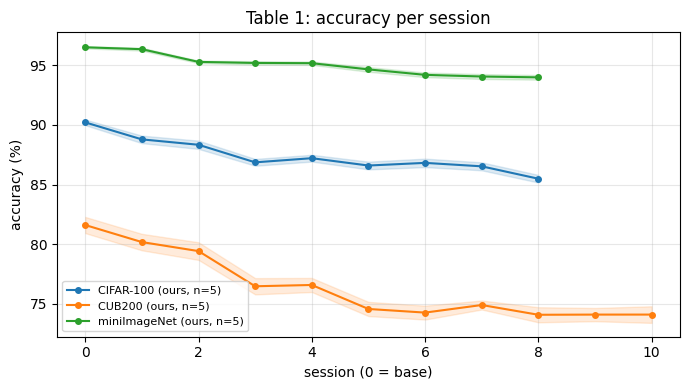

In [4]:
show('Table 1')

## 5. Table 3: ablation on CUB200
- **Baseline**: fine-tuning the pre-trained ViT (blocks 0–1 and the classifier in the base session, every parameter in
  the incremental sessions), classified with the prototype classifier; no prompts (`-ft -plain_ft`).
- **PKT**, **PKT + L_ED**, **PKT + L_SKD**: the method without one or both losses. **Ours** is the Table 1 CUB200 run.

**Table 3: ours vs. paper**

,seeds,A_Base ours,A_Base paper,Δ A_Base,A_Last ours,A_Last paper,Δ A_Last,A_Avg ours,A_Avg paper,Δ A_Avg
,,,,,,,,,,
Baseline (fine-tune + proto),5,80.52 ± 0.24,84.21 ± 0.13,-3.69,0.87 ± 0.53,3.79 ± 1.47,-2.92,13.59 ± 1.14,21.60 ± 1.32,-8.01
PKT,5,80.00 ± 1.01,79.06 ± 0.77,0.94,71.37 ± 0.88,70.81 ± 0.76,0.56,74.25 ± 0.86,73.36 ± 0.77,0.89
PKT + L_ED,5,79.72 ± 0.70,80.31 ± 0.54,-0.59,71.33 ± 0.96,72.70 ± 0.45,-1.37,74.05 ± 0.78,75.04 ± 0.40,-0.99
PKT + L_SKD,5,81.49 ± 0.89,82.10 ± 0.57,-0.61,73.75 ± 1.23,73.44 ± 0.40,0.31,76.06 ± 0.94,76.27 ± 0.30,-0.21
PriViLege (Ours),5,81.61 ± 0.68,82.21 ± 0.35,-0.60,74.11 ± 0.70,75.08 ± 0.52,-0.97,76.40 ± 0.60,77.50 ± 0.33,-1.10


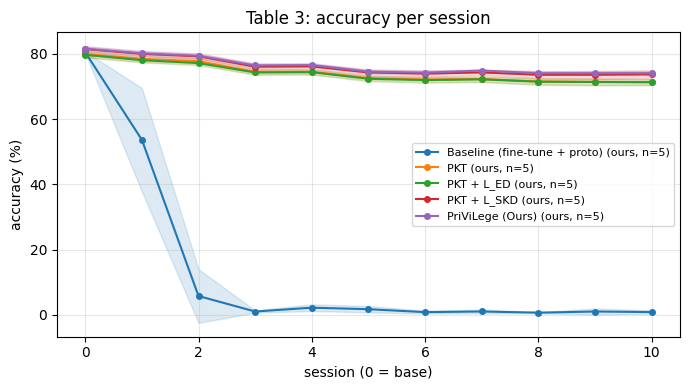

In [5]:
show('Table 3')

The released `-ft` option alone (`abl_Baseline`) is not the paper's Baseline: it keeps the classifier frozen at random
weights, runs the images through prompts left at random values, and builds the prototypes from a different feature
than the test images. It is listed here only to show the difference; Table 3 above uses `-ft -plain_ft`.

**Baseline variants: ours vs. paper**

,seeds,A_Base ours,A_Base paper,Δ A_Base,A_Last ours,A_Last paper,Δ A_Last,A_Avg ours,A_Avg paper,Δ A_Avg
,,,,,,,,,,
"Baseline, released -ft (not used)",5,38.39 ± 12.39,84.21 ± 0.13,-45.82,0.68 ± 0.30,3.79 ± 1.47,-3.11,4.62 ± 0.94,21.60 ± 1.32,-16.98
Baseline (fine-tune + proto),5,80.52 ± 0.24,84.21 ± 0.13,-3.69,0.87 ± 0.53,3.79 ± 1.47,-2.92,13.59 ± 1.14,21.60 ± 1.32,-8.01


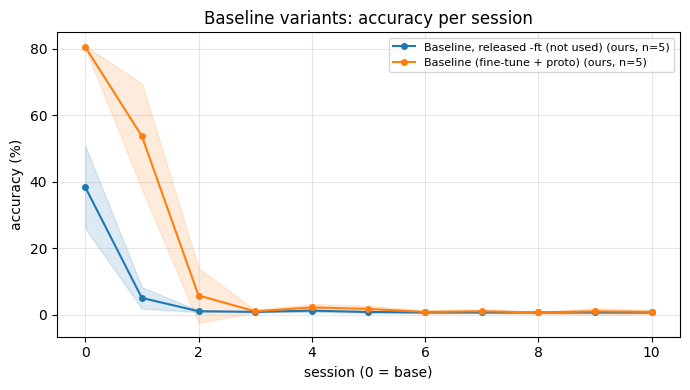

In [6]:
PAPER['Baseline variants'] = {('abl_Baseline', 'cub200'): PAPER['Table 3'][('abl_FT', 'cub200')],
                              ('abl_FT', 'cub200'):       PAPER['Table 3'][('abl_FT', 'cub200')]}
show('Baseline variants')

## 6. Table 4: number of tuned layers (CUB200)
Without the two losses, as in the paper; the 2-layer row is the PKT row of Table 3.

**Table 4: ours vs. paper**

,seeds,A_Base ours,A_Base paper,Δ A_Base,A_Last ours,A_Last paper,Δ A_Last,A_Avg ours,A_Avg paper,Δ A_Avg
,,,,,,,,,,
0 layers,5,75.59 ± 0.82,76.07 ± 0.56,-0.48,60.02 ± 1.12,60.19 ± 1.11,-0.17,66.74 ± 0.91,67.08 ± 0.71,-0.34
2 layers (= PKT),5,80.00 ± 1.01,79.06 ± 0.77,0.94,71.37 ± 0.88,70.81 ± 0.76,0.56,74.25 ± 0.86,73.36 ± 0.77,0.89
5 layers,5,74.87 ± 3.37,78.42 ± 0.84,-3.55,63.82 ± 3.60,68.52 ± 0.84,-4.70,67.89 ± 3.52,71.99 ± 0.84,-4.10
7 layers,5,72.60 ± 1.78,76.96 ± 0.74,-4.36,59.14 ± 1.66,63.15 ± 2.73,-4.01,64.29 ± 1.84,68.06 ± 1.54,-3.77
10 layers,5,76.10 ± 1.75,74.95 ± 0.78,1.15,60.65 ± 2.62,57.78 ± 2.30,2.87,66.40 ± 2.23,64.19 ± 1.59,2.21
12 layers,5,83.51 ± 1.53,73.62 ± 2.72,9.89,70.00 ± 1.44,56.02 ± 1.47,13.98,74.73 ± 1.44,62.71 ± 2.14,12.02


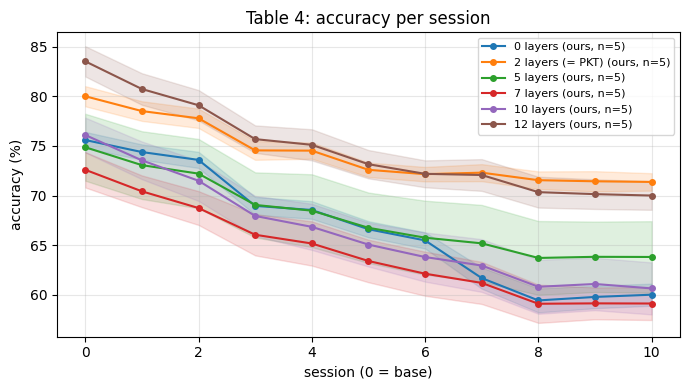

In [7]:
show('Table 4')

## 7. Figure 3: PriViLege on CLIP (CIFAR-100)
CLIP ViT-B/16 (LAION-2B). Dashed lines: the paper's curves, read off Figure 3.

**Figure 3: ours vs. paper**

,seeds,A_Base ours,A_Base paper,Δ A_Base,A_Last ours,A_Last paper,Δ A_Last,A_Avg ours,A_Avg paper,Δ A_Avg
,,,,,,,,,,
CLIP zero-shot,1,78.75 ± 0.00,78.80 (fig.),-0.05,71.00 ± 0.00,71.00 (fig.),0.00,73.78 ± 0.00,73.84 (fig.),-0.06
CLIP-PKT,5,83.34 ± 0.48,82.30 (fig.),1.04,62.86 ± 0.52,71.40 (fig.),-8.54,70.96 ± 0.43,75.48 (fig.),-4.52
CLIP-PKT + L_ED,5,83.34 ± 0.32,83.70 (fig.),-0.36,63.26 ± 0.57,74.70 (fig.),-11.44,71.17 ± 0.47,78.08 (fig.),-6.91
CLIP-PKT + L_ED + L_SKD,5,84.32 ± 0.36,84.20 (fig.),0.12,66.11 ± 0.52,77.10 (fig.),-10.99,73.25 ± 0.35,79.72 (fig.),-6.47


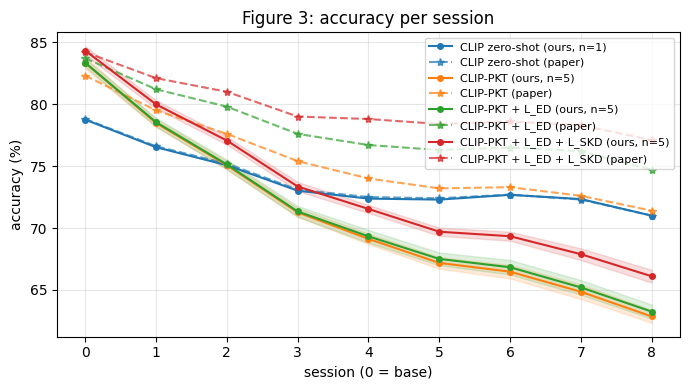

In [8]:
show('Figure 3')

## 8. Every comparison in one table

In [9]:
allrows = []
for t in ['Table 1', 'Table 3', 'Table 4', 'Figure 3']:
    for (name, ds), paper in PAPER[t].items():
        r = of(name, ds)
        row = {'table': t, 'row': label(t, name, ds), 'seeds': len(r)}
        for m, (pm, ps) in zip(METRICS, paper):
            row[m] = round(r[m].mean(), 2) if len(r) else np.nan
            row[f'Δ {m}'] = round(r[m].mean() - pm, 2) if len(r) else np.nan
        allrows.append(row)
alldf = pd.DataFrame(allrows).set_index(['table', 'row'])
display(alldf.style.map(color, subset=[f'Δ {m}' for m in METRICS]).format(precision=2, na_rep='—'))

## 9. Every run, seed by seed

In [10]:
cols = ['name', 'dataset', 'seed', 'A_Base', 'A_Last', 'A_Avg', 'minutes', 'resumed', 'commit', 'flags']
display(runs[cols].style.hide(axis='index').format(precision=2))

name,dataset,seed,A_Base,A_Last,A_Avg,minutes,resumed,commit,flags
PriViLege,cifar100,1,90.32,84.98,87.24,25.50,no,a51b049,-vit -comp_out 1 -LT -ED -SKD
PriViLege,cifar100,2,90.00,85.68,87.25,25.40,no,a51b049,-vit -comp_out 1 -LT -ED -SKD
PriViLege,cifar100,3,90.18,85.56,87.55,25.40,no,a51b049,-vit -comp_out 1 -LT -ED -SKD
PriViLege,cifar100,4,90.02,85.44,87.26,25.40,no,a51b049,-vit -comp_out 1 -LT -ED -SKD
PriViLege,cifar100,5,90.57,85.81,87.85,25.40,no,a51b049,-vit -comp_out 1 -LT -ED -SKD
PriViLege,cub200,1,82.02,74.91,76.84,6.60,no,a51b049,-vit -comp_out 1 -LT -ED -SKD
PriViLege,cub200,2,80.94,73.21,75.74,6.80,no,a51b049,-vit -comp_out 1 -LT -ED -SKD
PriViLege,cub200,3,81.63,74.13,76.46,6.80,no,a51b049,-vit -comp_out 1 -LT -ED -SKD
PriViLege,cub200,4,80.97,73.64,75.84,6.80,no,a51b049,-vit -comp_out 1 -LT -ED -SKD
PriViLege,cub200,5,82.51,74.65,77.10,6.80,no,a51b049,-vit -comp_out 1 -LT -ED -SKD
